# 03 - Feature engineering and leakage checks (Person 1)

Build with `python -m src.improved_features`; verify with `python -m src.leakage_checks`.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))   # make `src` importable from notebooks/
import pandas as pd, numpy as np
from IPython.display import Image, display
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
import json
from src.data_preprocessing import read_processed, PROCESSED_DIR, TABLES_DIR, RAW_DIR
from src.paper_features import verify_paper_features

## 1. Paper features F1 / F2 / F3 reconstructed from raw files
F1 = overall squad ratings, F2 = F1 + GK/DEF/MID/ATT ratings, F3 = 7 stats x 20 slots x 2 teams. The rebuild must equal the paper's released vectors cell for cell.

In [2]:
print(json.dumps(verify_paper_features(), indent=1))

{
 "F2": {
  "shape": [
   3791,
   10
  ],
  "all_cells_match": true,
  "cells_mismatching": 0,
  "rows_with_any_mismatch": 0,
  "max_abs_diff": 2.6645352591003757e-15
 },
 "F3": {
  "shape": [
   3791,
   280
  ],
  "all_cells_match": true,
  "cells_mismatching": 0,
  "rows_with_any_mismatch": 0,
  "max_abs_diff": 2.842170943040401e-14
 }
}


**Important:** these ratings are *end-of-season* aggregates weighted by minutes played in the match, so they are not available before kick-off. The paper-faithful features are kept for the reproduction; the engineered features below are pre-match.

## 2. Engineered dataset

In [3]:
eng = read_processed('features_engineered.csv')
groups = json.loads((PROCESSED_DIR / 'feature_groups.json').read_text())
print(eng.shape)
pd.Series({k: len(v) for k, v in groups.items()}, name='columns')

(3790, 146)


paper_F1             2
paper_F2            10
recent_form_w3      18
differences_w3       9
recent_form_w5      18
differences_w5       9
recent_form_w10     18
differences_w10      9
elo                  3
elo_extra            2
venue_form          10
differences         19
prematch_ratings    17
history_counts       2
Name: columns, dtype: int64

In [4]:
eng[['date','home_team','away_team','result','h_elo','a_elo','elo_diff','h_points_last5','a_points_last5','diff_points_last5','h_home_ppg_last10','a_away_ppg_last10']].tail(8)

,date,home_team,away_team,result,h_elo,a_elo,elo_diff,h_points_last5,a_points_last5,diff_points_last5,h_home_ppg_last10,a_away_ppg_last10
3782,2019-05-12,Crystal Palace,Bournemouth,H,1497.179573,1448.847581,48.331992,10.0,7.0,3.0,0.9,0.7
3783,2019-05-12,Fulham,Newcastle,A,1342.329267,1458.699261,-116.369994,9.0,7.0,2.0,1.3,0.7
3784,2019-05-12,Leicester,Chelsea,D,1495.158044,1602.063076,-106.905032,7.0,8.0,-1.0,1.5,1.3
3785,2019-05-12,Liverpool,Wolves,H,1759.297071,1502.343386,256.953684,15.0,10.0,5.0,2.8,1.2
3786,2019-05-12,Man Utd,Cardiff,A,1595.513715,1352.142752,243.370963,5.0,3.0,2.0,2.1,1.0
3787,2019-05-12,Southampton,Huddersfield,D,1432.556588,1270.495679,162.060909,5.0,1.0,4.0,1.4,0.1
3788,2019-05-12,Tottenham,Everton,D,1600.569535,1527.929909,72.639625,6.0,10.0,-4.0,1.9,1.3
3789,2019-05-12,Watford,West Ham,A,1467.908983,1469.956081,-2.047097,4.0,7.0,-3.0,1.5,0.7


## 3. Leakage checks

In [5]:
rep = json.loads((TABLES_DIR / 'leakage_report.json').read_text())
{k: v for k, v in rep.items() if k != '6_top_correlations_vs_goal_diff'}

{'1_chronology': {'sorted_by_date': True,
  'team_twice_same_day': 0,
  'teams_not_38_games_per_season': 0},
 '2_brute_force': {'values_checked': 5579, 'mismatches': 0, 'examples': []},
 '3_perturbation': {'trials': 8,
  'own_features_changed': 0,
  'earlier_or_same_day_features_changed': 0,
  'later_matches_of_involved_teams_unchanged': 0},
 '4_no_target_columns': {'groups_checked': 14,
  'groups_with_target_like_columns': {}},
 '5_prematch_ratings': {'pm_columns': 15,
  '0910_rows_all_nan': True,
  'mean_starter_coverage_1011_onwards': 0.737},
 'ALL_PASSED': True}

## 4. Feature analysis

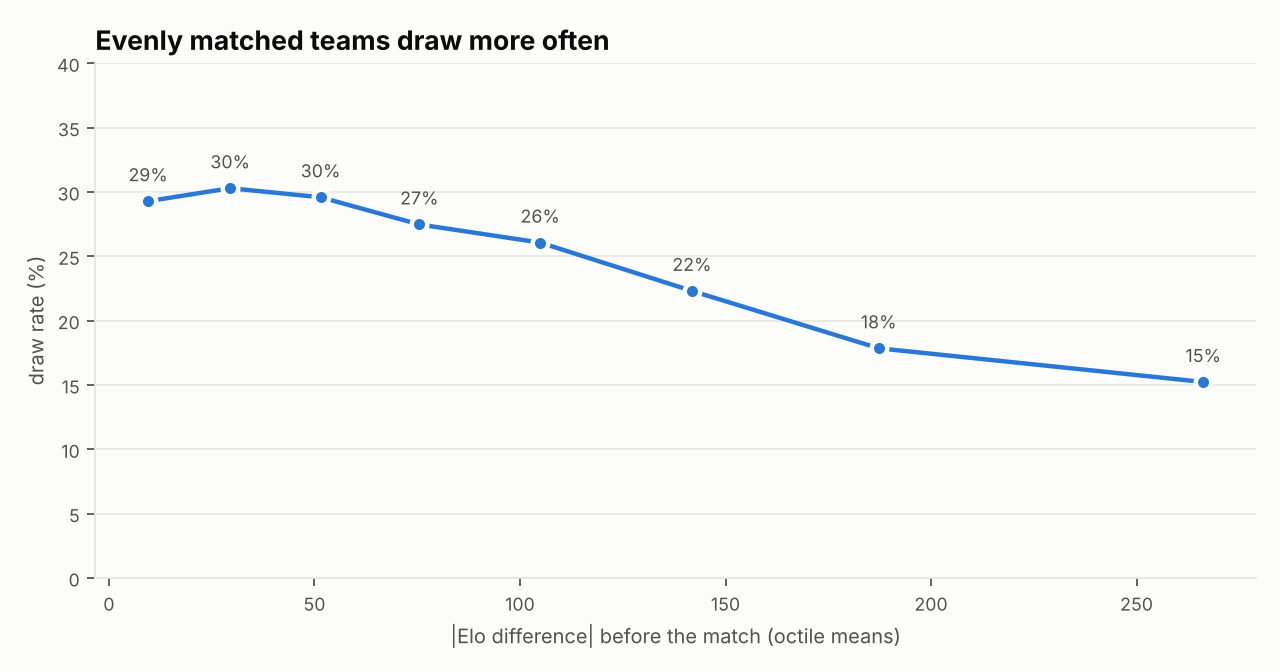

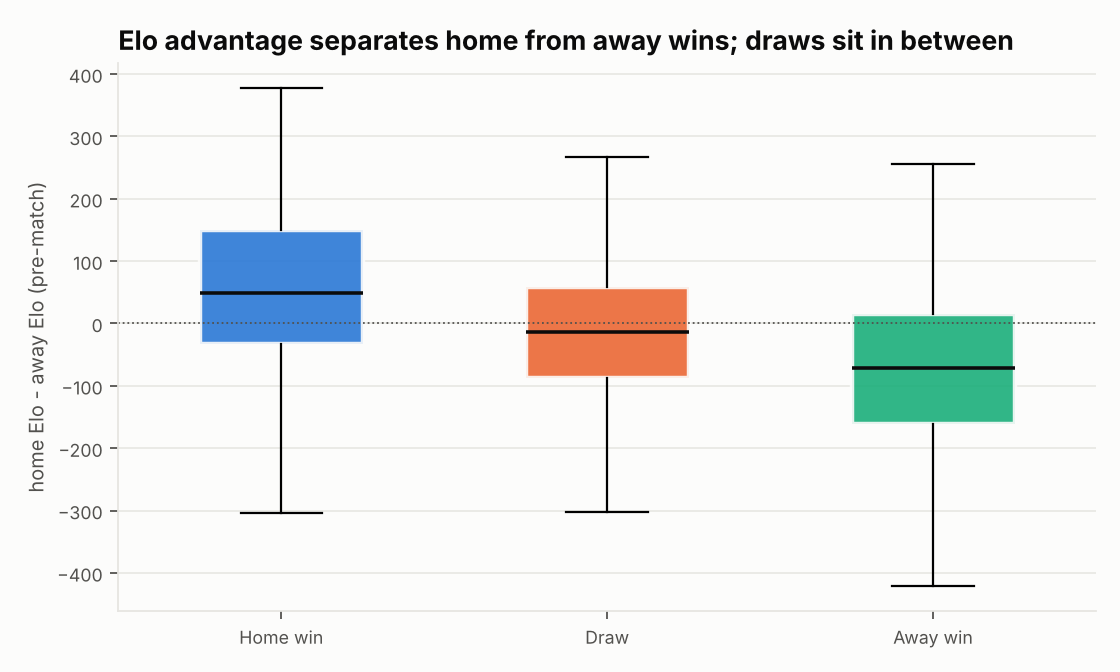

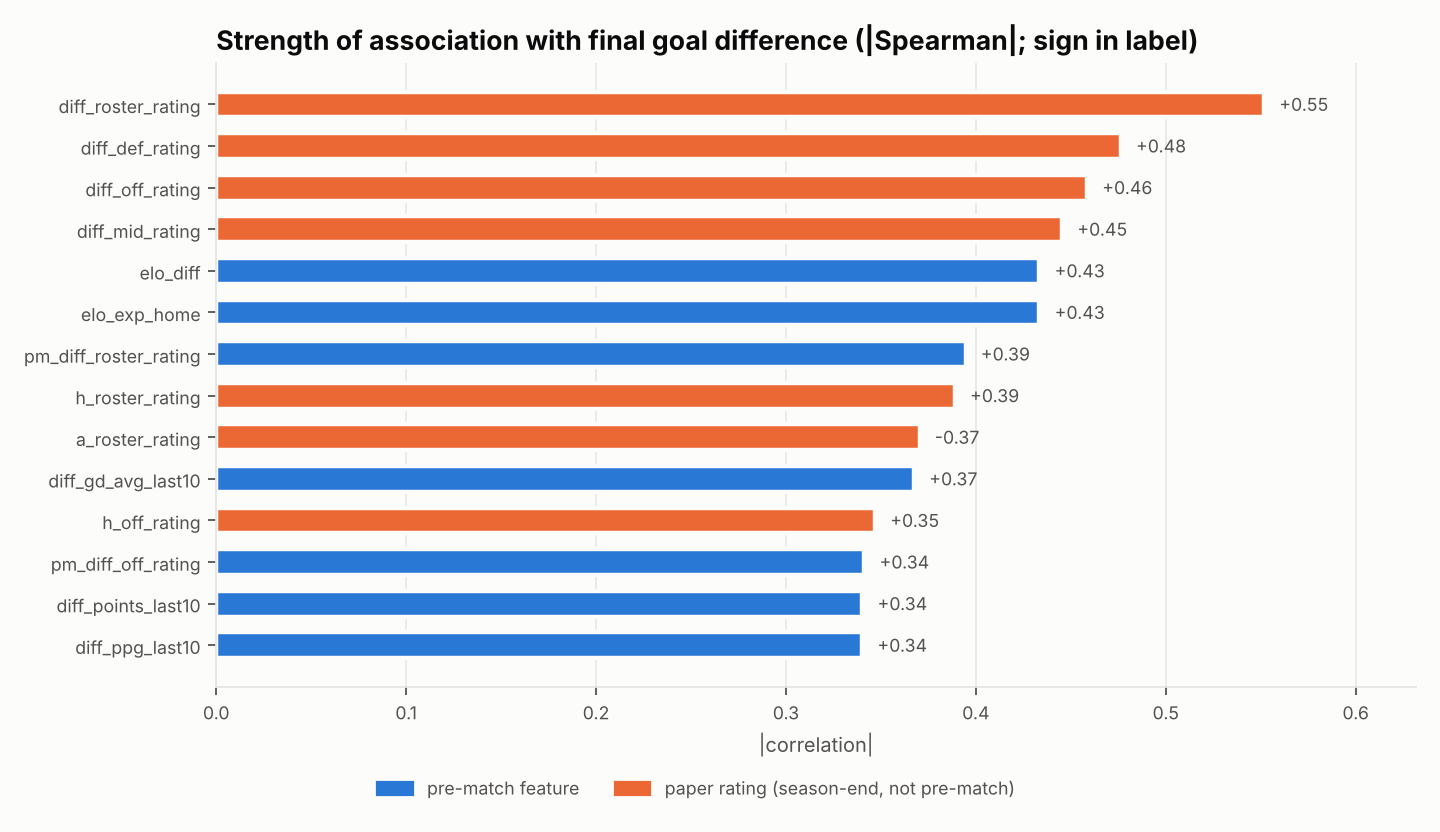

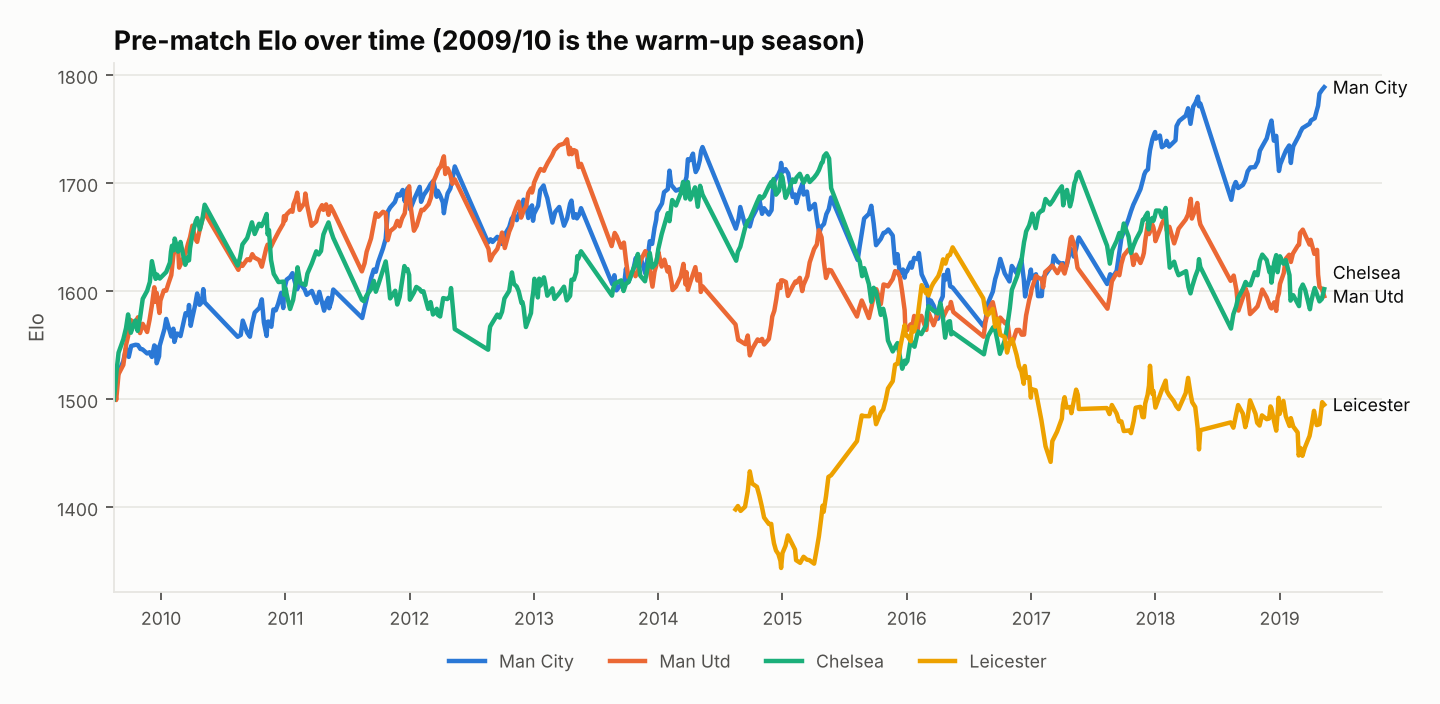

In [6]:
for f in ['02_draw_rate_vs_elo_gap', '03_elo_diff_by_outcome', '04_top_feature_correlations', '05_elo_trajectories']:
    display(Image(str(pathlib.Path.cwd().parent / f'results/figures/{f}.png')))

In [7]:
pd.read_csv(TABLES_DIR / 'feature_missingness.csv').head(12)

,feature,missing,missing_pct
0,pm_diff_gk_rating,1978,52.19
1,pm_a_gk_rating,1295,34.17
2,pm_h_gk_rating,1289,34.01
3,pm_diff_off_rating,1091,28.79
4,pm_diff_mid_rating,1074,28.34
5,pm_diff_def_rating,987,26.04
6,pm_h_off_rating,761,20.08
7,pm_a_off_rating,750,19.79
8,pm_a_mid_rating,746,19.68
9,pm_h_mid_rating,730,19.26
